# Disease Prediction from Medical Data
### CodeAlpha Machine Learning Internship — Task 2

**Objective:** Predict whether a patient has diabetes from diagnostic measurements.

**Dataset:** Pima Indians Diabetes  — 768 female patients of Pima Indian heritage, aged 21+, with 8 medical features and a binary outcome (1 = diabetic, 0 = not).

**Approach:** Classification with Logistic Regression, SVM, Random Forest and XGBoost, using Accuracy, Precision, Recall, F1-Score and ROC-AUC.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed - run `pip install xgboost` to include it. Continuing without it.")

sns.set_style("whitegrid")


## 1. Load the data


In [3]:
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
df = pd.read_csv(r"C:\Users\User\Desktop\disease-prediction\pima-indians-diabetes.csv", header=None, names=cols)
print(df.shape)
df.head()


(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Explore the data

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [5]:
df["Outcome"].value_counts(normalize=True).rename("proportion")


Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64

## 3.  missing values

The minimum values above: Glucose, BloodPressure, SkinThickness, Insulin and BMI have minimums of **0**, which is biologically impossible. In this dataset, 0 is a placeholder for a missing measurement.

In [6]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zeros per column (these are really missing values):")
print((df[zero_cols] == 0).sum())

df[zero_cols] = df[zero_cols].replace(0, np.nan)
print("\nMissing % after conversion:")
print((df[zero_cols].isnull().mean() * 100).round(1))


Zeros per column (these are really missing values):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing % after conversion:
Glucose           0.7
BloodPressure     4.6
SkinThickness    29.6
Insulin          48.7
BMI               1.4
dtype: float64


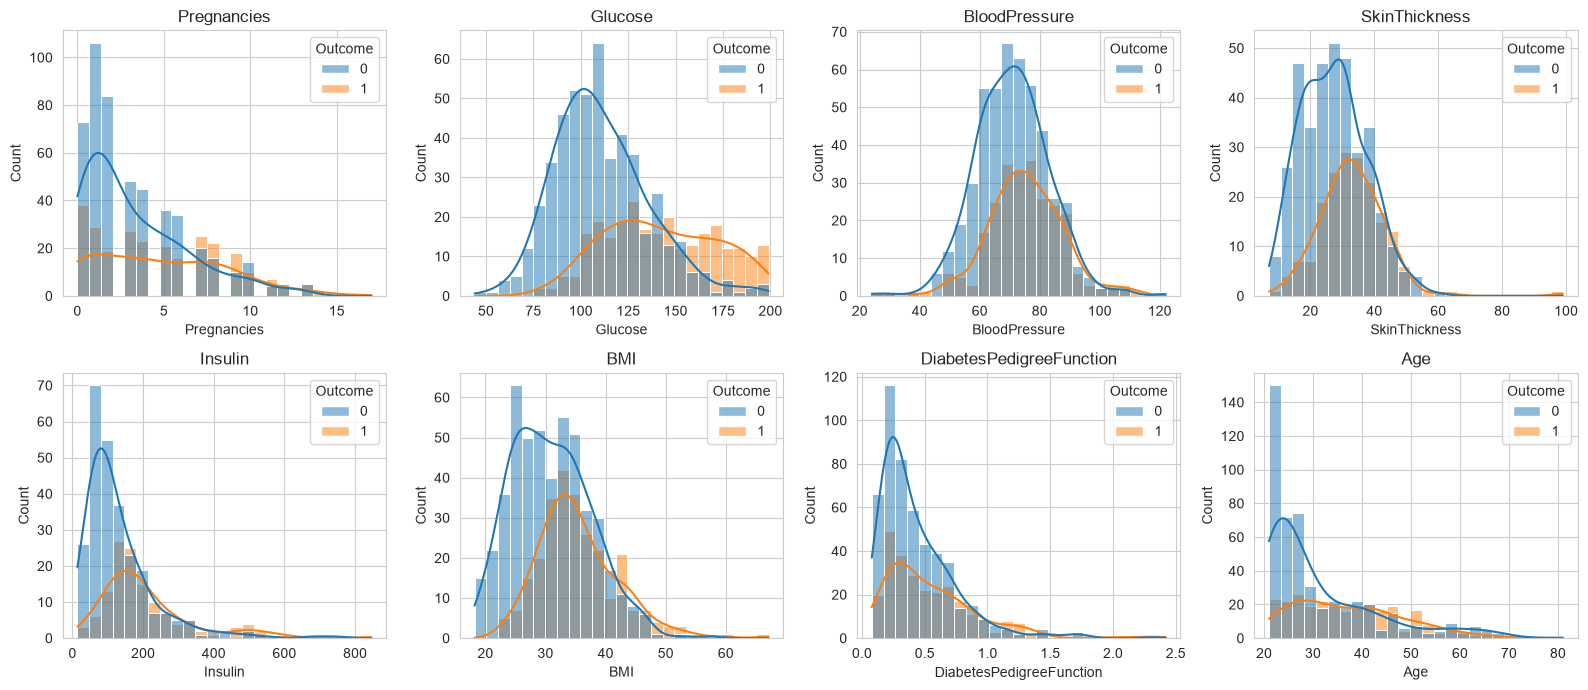

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
features = [c for c in df.columns if c != "Outcome"]
for ax, col in zip(axes.flat, features):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, ax=ax, bins=25)
    ax.set_title(col)
plt.tight_layout()
plt.show()


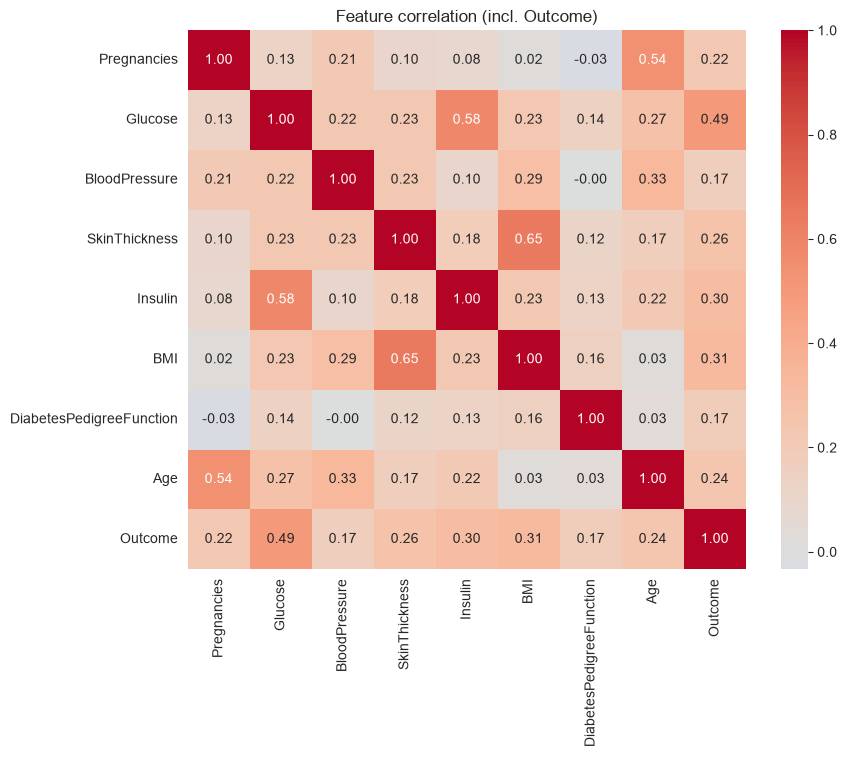

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature correlation (incl. Outcome)")
plt.show()


## 4. Feature 

Two simple derived features:

- **Glucose × BMI** — captures the combined metabolic risk
- **Age group** — risk changes non-linearly with age

In [9]:
df["Glucose_BMI"] = df["Glucose"] * df["BMI"]
df["AgeGroup"] = pd.cut(df["Age"], bins=[20, 30, 40, 50, 100], labels=[0, 1, 2, 3]).astype(int)

X = df.drop(columns=["Outcome"])
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (614, 10) Test: (154, 10)


## 5. Build the models

Each model is wrapped in a **Pipeline** that imputes missing values (median) and scales features.

In [10]:
def make_pipe(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=1000, random_state=42)),
    "SVM (RBF)": make_pipe(SVC(probability=True, random_state=42)),
    "Random Forest": make_pipe(RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)),
}
if HAS_XGB:
    models["XGBoost"] = make_pipe(XGBClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05,
        eval_metric="logloss", random_state=42))
list(models)


['Logistic Regression', 'SVM (RBF)', 'Random Forest', 'XGBoost']

## 6. Cross-validation


In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_results[name] = scores
    print(f"{name:22s} CV ROC-AUC: {scores.mean():.3f} (+/- {scores.std():.3f})")


Logistic Regression    CV ROC-AUC: 0.847 (+/- 0.018)
SVM (RBF)              CV ROC-AUC: 0.834 (+/- 0.024)


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_bas

Random Forest          CV ROC-AUC: 0.829 (+/- 0.026)
XGBoost                CV ROC-AUC: 0.813 (+/- 0.025)


In [12]:
rows, probas, preds = [], {}, {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    preds[name], probas[name] = pred, proba
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.727,0.625,0.556,0.588,0.814
SVM (RBF),0.740,0.659,0.537,0.592,0.809
Random Forest,0.740,0.659,0.537,0.592,0.814
XGBoost,0.760,0.667,0.630,0.648,0.824


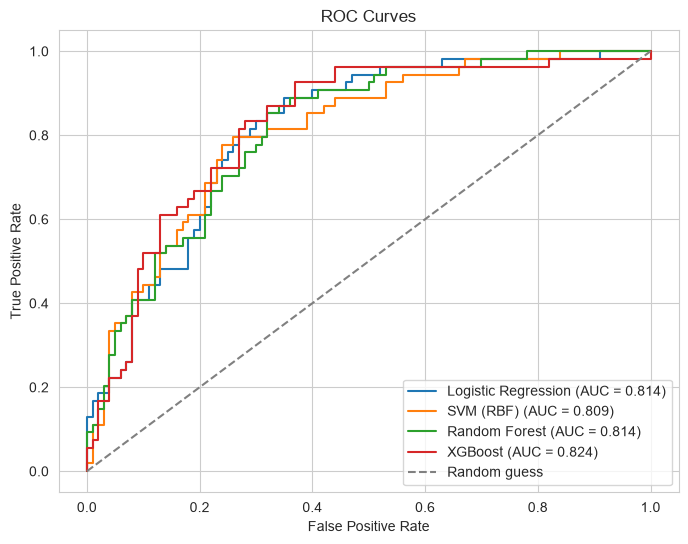

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves")
ax.legend()
plt.show()


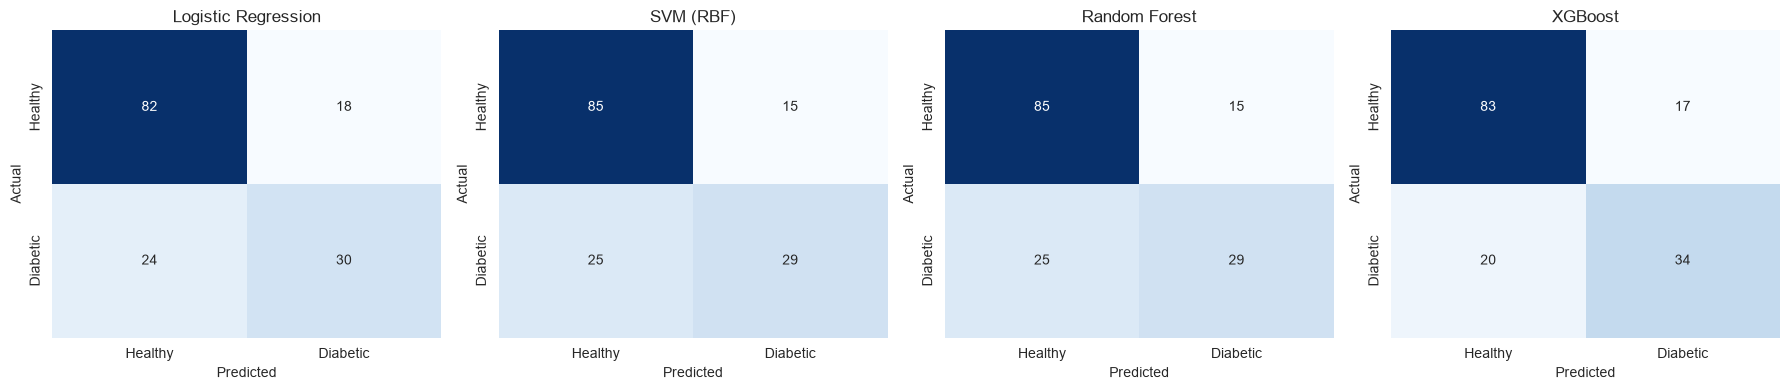

In [14]:
n = len(models)
fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 4))
axes = np.atleast_1d(axes)
for ax, (name, pred) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=["Healthy", "Diabetic"], yticklabels=["Healthy", "Diabetic"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


## 8.Random Forest

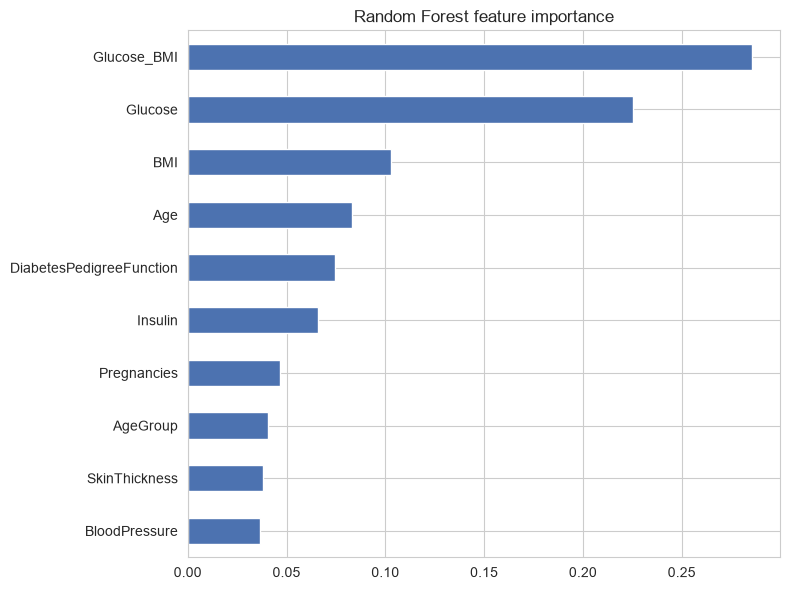

In [15]:
rf_pipe = models["Random Forest"]
importances = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", figsize=(8, 6), color="#4C72B0", title="Random Forest feature importance")
plt.tight_layout()
plt.show()


In [16]:
best_name = results["ROC-AUC"].idxmax()
print("Best model by ROC-AUC:", best_name)
proba = probas[best_name]

rows = []
for t in [0.3, 0.35, 0.4, 0.45, 0.5]:
    p = (proba >= t).astype(int)
    rows.append({"Threshold": t,
                 "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p),
                 "F1-Score": f1_score(y_test, p)})
pd.DataFrame(rows).set_index("Threshold").round(3)


Best model by ROC-AUC: XGBoost


,Precision,Recall,F1-Score
Threshold,,,
0.30,0.614,0.796,0.694
0.35,0.619,0.722,0.667
0.40,0.632,0.667,0.649
0.45,0.654,0.630,0.642
0.50,0.667,0.630,0.648


## 10. Conclusion

- The dataset's hidden missing values (zeros in Glucose, BloodPressure, SkinThickness, Insulin, BMI) were the key cleaning step.
- Compare the models in the results table above: on a small dataset like this one (768 rows), simple models such as Logistic Regression are often competitive with Random Forest and XGBoost, so more complex does not automatically mean better.
- **Glucose** is the strongest predictor, followed by BMI and Age, which matches known diabetes risk factors.


